# CA1 — Exploratory Data Analysis & Data Preparation
## Smart Home Energy Dataset

**Module:** Data Preparation & Visualisation
**Student:** Rian Kadi
**Institution:** CCT College Dublin
**Date:** October 2026

---

### Purpose of this notebook

This notebook carries out an exploratory analysis and preparation of the `Smart_Home_Energy.csv`
dataset so that it is fit for predictive modelling. The target of any future model would be
`monthly_bill_eur` (household energy cost), with the remaining variables as predictors.

The notebook follows a deliberate order, because the order changes the result:

| Step | Why it comes here |
|---|---|
| 1. Inspect | Establish a baseline before changing anything |
| 2. Remove duplicates | Done **before** imputation, so repeated rows do not distort the medians used to fill gaps |
| 3. Standardise categories | Merge split labels before any grouping or encoding |
| 4. Detect & treat outliers | Convert implausible values to missing rather than deleting whole rows |
| 5. Impute missing values | Fill original gaps *and* the gaps created in step 4 |
| 6. Feature selection | Judge predictors on the cleaned data, not the corrupted data |
| 7. Visualise | Evidence the decisions taken |

Every decision below is stated with its justification, as required by the assessment brief.

---
## 1. Setup and data import

In [ ]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display and plot settings
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 200
plt.rcParams['savefig.bbox'] = 'tight'

# Folder to save figures for the poster
import os
os.makedirs('figures', exist_ok=True)

print('pandas', pd.__version__)
print('numpy ', np.__version__)

In [12]:
# Load the dataset.
# The CSV must sit in the SAME folder as this notebook.
df = pd.read_csv('Smart_Home_Energy.csv')

# Keep an untouched copy of the raw data so we can compare before vs after cleaning
df_raw = df.copy()

print('Dataset loaded successfully')
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])

Dataset loaded successfully
Rows: 5507
Columns: 8


---
## 2. Initial inspection

Before changing anything, establish what the data actually looks like.

In [13]:
# First five records
df.head()

,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
0,Semi-detached,Heat Pump,Standard,2,173.7,5.4,18.84,176.72
1,Detached,Gas,Smart,1,131.8,11.1,9.95,96.82
2,Semi-detached,Electric,Smart,4,146.5,12.6,19.54,239.75
3,Semi-detached,Oil,Smart,6,72.4,11.7,14.34,139.45
4,Semi-detached,Heat Pump,Smart,3,170.2,9.2,14.73,148.39


In [14]:
# Structure: column names, non-null counts, data types, memory use
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5507 entries, 0 to 5506
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   dwelling_type       5507 non-null   str    
 1   heating_type        5462 non-null   str    
 2   tariff_type         5416 non-null   str    
 3   occupants           5507 non-null   int64  
 4   floor_area_m2       5388 non-null   float64
 5   avg_outdoor_temp_c  5373 non-null   float64
 6   avg_daily_use_kwh   5450 non-null   float64
 7   monthly_bill_eur    5441 non-null   float64
dtypes: float64(4), int64(1), str(3)
memory usage: 467.0 KB


In [15]:
# Summary statistics for the numeric columns
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
occupants,5507.0,3.62,1.86,1.0,2.00,4.00,5.00,20.00
floor_area_m2,5388.0,126.09,78.36,30.3,86.80,116.20,151.70,946.70
avg_outdoor_temp_c,5373.0,10.29,5.43,-27.9,7.10,10.30,13.50,46.00
avg_daily_use_kwh,5450.0,19.39,16.43,5.0,13.49,17.37,21.28,219.42
monthly_bill_eur,5441.0,196.92,190.92,40.0,122.60,169.05,228.82,2788.41


In [16]:
# Summary of the categorical (text) columns
df.describe(include='object').T

C:\Users\adamk\AppData\Local\Temp\ipykernel_4712\3672151770.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
dwelling_type,5507,5,Semi-detached,1626
heating_type,5462,4,Gas,2260
tariff_type,5416,4,Standard,2473


### Observation from the initial inspection

| Column | Type | Issue visible already |
|---|---|---|
| `dwelling_type` | categorical | 5 unique values, but only 4 real property types exist |
| `heating_type` | categorical | missing values present |
| `tariff_type` | categorical | 4 unique values, but only 3 real tariffs exist |
| `occupants` | integer | maximum of 20 — implausible for a household |
| `floor_area_m2` | float | maximum of 946.7 m² — implausible for a dwelling |
| `avg_outdoor_temp_c` | float | range of −27.9 °C to 46.0 °C — impossible for Ireland |
| `avg_daily_use_kwh` | float | maximum of 219.4 kWh/day — roughly 11× the median |
| `monthly_bill_eur` | float | maximum of €2,788 — roughly 16× the median |

The `count` row of `describe()` is also lower than the total row count for several
columns, which confirms missing data.

---
## 3. Missing values

### 3.1 Quantify the gaps

In [17]:
# Count and percentage of missing values per column
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('missing_count', ascending=False)

missing

,missing_count,missing_pct
avg_outdoor_temp_c,134,2.43
floor_area_m2,119,2.16
tariff_type,91,1.65
monthly_bill_eur,66,1.20
avg_daily_use_kwh,57,1.04
heating_type,45,0.82
occupants,0,0.00
dwelling_type,0,0.00


In [18]:
# How many ROWS are affected, and are gaps concentrated or spread out?
print('Total rows:', len(df))
print('Rows with at least one missing value:', df.isnull().any(axis=1).sum())
print('Percentage of rows affected:',
      round(df.isnull().any(axis=1).sum() / len(df) * 100, 2), '%')
print()
print('Number of missing values per row:')
print(df.isnull().sum(axis=1).value_counts().sort_index())

Total rows: 5507
Rows with at least one missing value: 495
Percentage of rows affected: 8.99 %

Number of missing values per row:
0    5012
1     478
2      17
Name: count, dtype: int64


**Why this matters:** 495 rows (9.0%) contain at least one gap, but almost all of those rows
(478) are missing only a *single* value. Deleting these rows would discard roughly 9% of the
dataset — and with it, seven perfectly valid measurements per row — to remove one unknown value.

**Decision:** impute rather than delete. This is justified because the proportion missing in any
single column is low (0.8%–2.4%), well under the ~5% threshold at which imputation is generally
considered low-risk, and the gaps are scattered rather than clustered in one part of the data.

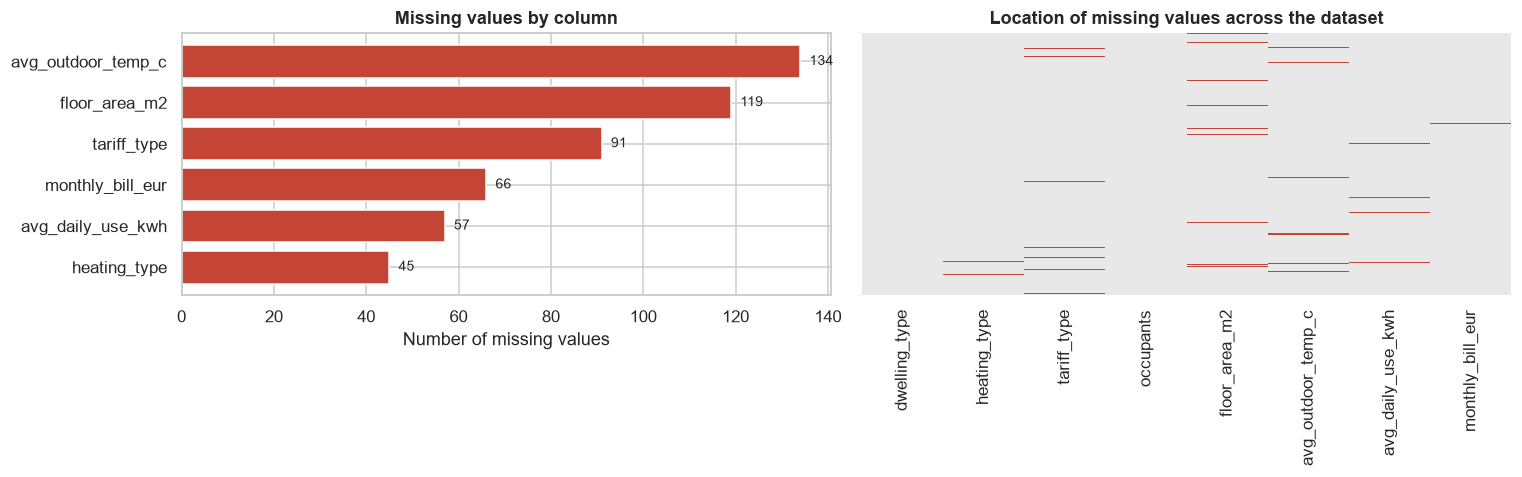

In [19]:
# Visualise the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Left: count of missing values per column
m = missing[missing['missing_count'] > 0].sort_values('missing_count')
axes[0].barh(m.index, m['missing_count'], color='#C44536')
axes[0].set_title('Missing values by column', fontweight='bold')
axes[0].set_xlabel('Number of missing values')
for i, v in enumerate(m['missing_count']):
    axes[0].text(v + 2, i, str(v), va='center', fontsize=9)

# Right: heatmap showing WHERE the gaps sit in the dataset
sns.heatmap(df.isnull(), cbar=False, yticklabels=False,
            cmap=['#E8E8E8', '#C44536'], ax=axes[1])
axes[1].set_title('Location of missing values across the dataset', fontweight='bold')

plt.tight_layout()
plt.savefig('figures/fig1_missing_values.png')
plt.show()

The heatmap shows the gaps are **randomly scattered** rather than forming blocks or stripes.
There is no evidence that missingness depends on the value itself (for example, no sign that
high bills are systematically absent). This supports treating the data as *Missing At Random*,
which is the condition under which median and mode imputation is appropriate.

*Imputation is performed in Section 7, after outlier treatment, so that implausible values do
not contaminate the medians used to fill the gaps.*

---
## 4. Duplicate records

### 4.1 Detect

In [20]:
# Exact duplicate rows (every one of the 8 fields identical)
dupe_count = df.duplicated().sum()
print('Exact duplicate rows found:', dupe_count)
print('As a percentage of the dataset:', round(dupe_count / len(df) * 100, 2), '%')

Exact duplicate rows found: 157
As a percentage of the dataset: 2.85 %


In [21]:
# Inspect some examples to confirm they are true duplicates, not coincidence
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(8)

,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur
1600,Apartment,Electric,Night Saver,1,98.4,16.5,14.63,126.41
2679,Apartment,Electric,Night Saver,1,98.4,16.5,14.63,126.41
541,Apartment,Electric,Smart,3,76.9,5.4,16.07,120.13
2396,Apartment,Electric,Smart,3,76.9,5.4,16.07,120.13
2197,Apartment,Electric,Smart,5,87.9,17.1,25.11,296.06
3189,Apartment,Electric,Smart,5,87.9,17.1,25.11,296.06
3002,Apartment,Electric,Smart,6,114.8,3.7,30.95,430.88
5273,Apartment,Electric,Smart,6,114.8,3.7,30.95,430.88


### 4.2 Justification for removal

These are **exact** duplicates: all eight fields match, including continuous measurements
recorded to one or two decimal places. The probability of two genuinely separate households
independently matching on floor area, outdoor temperature, daily consumption *and* monthly bill
to that precision is effectively zero. They are therefore recording or merge artefacts, not
real observations.

Leaving them in would:
- **bias summary statistics** — duplicated rows are counted twice in every mean and median;
- **distort imputation** — the medians used to fill missing values would be pulled toward
  whichever rows happened to be duplicated;
- **inflate apparent sample size** and, in later modelling, leak identical rows into both the
  training and test sets, producing falsely optimistic accuracy.

**Decision:** remove exact duplicates, keeping the first occurrence of each.

In [22]:
# Remove duplicates, keeping the first occurrence
rows_before = len(df)
df = df.drop_duplicates(keep='first').reset_index(drop=True)
rows_after = len(df)

print(f'Rows before : {rows_before}')
print(f'Rows removed: {rows_before - rows_after}')
print(f'Rows after  : {rows_after}')
print('Duplicates remaining:', df.duplicated().sum())

Rows before : 5507
Rows removed: 157
Rows after  : 5350
Duplicates remaining: 0


---
## 5. Categorical consistency

### 5.1 Inspect the category labels

In [23]:
# List every distinct value in each categorical column
for col in ['dwelling_type', 'heating_type', 'tariff_type']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- dwelling_type ---
dwelling_type
Semi-detached    1587
Detached         1283
Terraced         1253
Apartment        1182
Semi Detached      45
Name: count, dtype: int64

--- heating_type ---
heating_type
Gas          2195
Heat Pump    1526
Electric      817
Oil           767
NaN            45
Name: count, dtype: int64

--- tariff_type ---
tariff_type
Standard       2398
Smart          1843
Night Saver     978
NaN              90
smart            41
Name: count, dtype: int64



### 5.2 Problems identified

| Column | Problem | Evidence |
|---|---|---|
| `dwelling_type` | `Semi-detached` and `Semi Detached` are the same property type recorded two ways | 1,626 vs 47 records — a clear dominant spelling and a minority variant |
| `tariff_type` | `Smart` and `smart` differ only in capitalisation | 1,897 vs 42 records |

**Why this must be fixed:** Python treats strings as case- and character-sensitive, so
`'Smart' != 'smart'`. If left uncorrected, any `groupby`, pivot table, or one-hot encoding would
create **separate categories for the same real-world thing**. A model would then be fitted on a
"smart" category containing only 42 households — a group far too small to learn anything
reliable from — while the true Smart-tariff group is understated by the same 42 households.

**Decision:** normalise the text (strip whitespace, convert hyphens and multiple spaces to a
single consistent form, apply title case) and map the variants onto the dominant label.

In [24]:
# Standardise the text of every categorical column
cat_cols = ['dwelling_type', 'heating_type', 'tariff_type']

for col in cat_cols:
    df[col] = (df[col]
               .str.strip()            # remove leading/trailing spaces
               .str.replace(r'\s+', ' ', regex=True)   # collapse repeated spaces
               .str.title())           # consistent capitalisation: 'smart' -> 'Smart'

# Map the remaining spelling variant onto the dominant label
df['dwelling_type'] = df['dwelling_type'].replace({'Semi Detached': 'Semi-Detached'})

# Confirm the fix
for col in cat_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- dwelling_type ---
dwelling_type
Semi-Detached    1632
Detached         1283
Terraced         1253
Apartment        1182
Name: count, dtype: int64

--- heating_type ---
heating_type
Gas          2195
Heat Pump    1526
Electric      817
Oil           767
NaN            45
Name: count, dtype: int64

--- tariff_type ---
tariff_type
Standard       2398
Smart          1884
Night Saver     978
NaN              90
Name: count, dtype: int64



Each categorical column now contains only its genuine categories. `dwelling_type` has reduced
from 5 labels to 4, and `tariff_type` from 4 to 3, matching the data dictionary.

---
## 6. Outlier detection

This is the most consequential step in the notebook, so the reasoning is set out in full.

Two separate tests are applied, because the dataset contains two different *kinds* of
implausible value:

- **Test A — domain plausibility and distribution gaps.** Does the value make physical sense,
  and is it separated from the legitimate data by a visible gap?
- **Test B — internal consistency.** Does the value contradict the other fields in its own row?

A value is only treated as an error when it fails at least one of these tests. The statistical
IQR rule is used as a first screen, but **not** as the sole basis for removal — a value can sit
outside the IQR fence and still be a genuine, informative observation.

### 6.1 First screen: the IQR rule

In [25]:
num_cols = ['occupants', 'floor_area_m2', 'avg_outdoor_temp_c',
            'avg_daily_use_kwh', 'monthly_bill_eur']

def iqr_bounds(series):
    """Return the lower and upper Tukey fences (Q1 - 1.5*IQR, Q3 + 1.5*IQR)."""
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

summary = []
for col in num_cols:
    lo, hi = iqr_bounds(df[col])
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()
    summary.append({
        'column': col,
        'min': round(df[col].min(), 2),
        'max': round(df[col].max(), 2),
        'lower_fence': round(lo, 2),
        'upper_fence': round(hi, 2),
        'n_outliers': n_out,
        'pct': round(n_out / df[col].notna().sum() * 100, 2)
    })

pd.DataFrame(summary)

,column,min,max,lower_fence,upper_fence,n_outliers,pct
0,occupants,1.0,20.00,-2.50,9.50,25,0.47
1,floor_area_m2,30.3,946.70,-9.63,248.18,58,1.11
2,avg_outdoor_temp_c,-27.9,46.00,-2.50,23.10,64,1.23
3,avg_daily_use_kwh,5.0,219.42,1.87,32.95,140,2.64
4,monthly_bill_eur,40.0,2788.41,-37.13,389.28,146,2.76


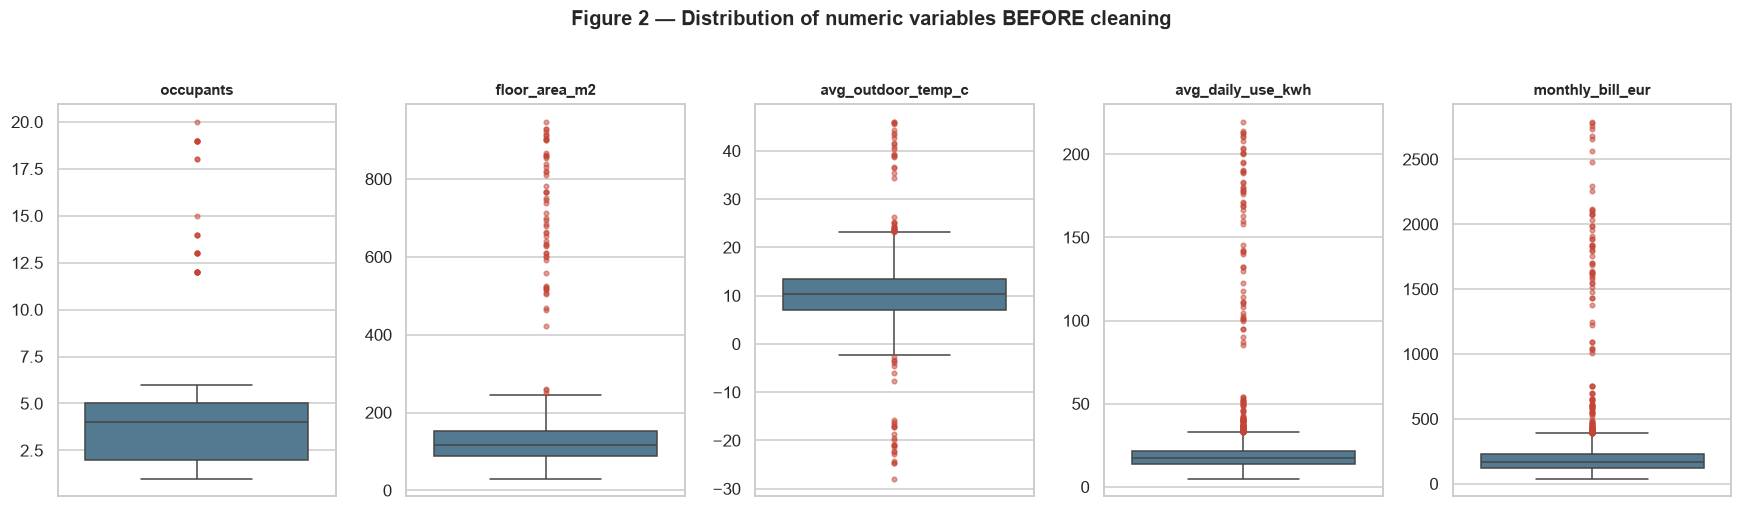

In [27]:
# Boxplots of the raw numeric data - each variable on its own axis because the scales differ
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='#4A7C9B',
                flierprops={'marker': 'o', 'markersize': 3,
                            'markerfacecolor': '#C44536',
                            'markeredgecolor': '#C44536', 'alpha': 0.5})
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_ylabel('')

fig.suptitle('Figure 2 — Distribution of numeric variables BEFORE cleaning',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('figures/fig2_boxplots_before.png')
plt.show()

The boxplots show heavy right-hand tails on `floor_area_m2`, `avg_daily_use_kwh` and
`monthly_bill_eur`, and tails on both sides of `avg_outdoor_temp_c`. The IQR rule alone,
however, cannot tell us whether those points are **errors** or **genuine extreme households**.
That distinction is what Tests A and B establish below.

**Mild versus extreme outliers.** Tukey (1977) defines two fences, not one. The *inner* fence
at Q3 + 1.5 x IQR marks a **mild** outlier; the *outer* fence at Q3 + 3 x IQR marks an
**extreme** ("far out") observation. This distinction is used deliberately in this notebook:

- Points beyond the **inner** fence are **retained**. A skewed variable such as household energy
  use will always produce a long right tail, and those households are real customers a model
  must be able to price.
- Points beyond the **outer** fence are **investigated**, and treated only where a second test
  confirms they are errors.

Applying the 1.5 x IQR rule as an automatic delete would have removed 144 consumption records
and 151 bill records — roughly 2.7% of the data each — much of it legitimate.

### 6.2 Test A — distribution gaps

If implausible values were introduced artificially, they tend to sit *apart* from the real data
rather than tapering off it. Checking the sorted values for a gap is a simple, decisive test.

In [ ]:
# Look for a break between the legitimate block of values and the suspect block
for col, cut in [('occupants', 6), ('floor_area_m2', 300)]:
    s = df[col].dropna().sort_values()
    print(f'--- {col} ---')
    print('  highest values below the suspected break :', s[s <= cut].tail(4).round(1).tolist())
    print('  lowest values above the suspected break  :', s[s > cut].head(4).round(1).tolist())
    print('  maximum                                  :', round(s.max(), 1))
    print()

# Full value counts for occupants - the gap is unmistakable here
print('Counts for every observed value of occupants:')
print(df['occupants'].value_counts().sort_index())

**Finding — `occupants`:** the data contains households of 1, 2, 3, 4, 5 and 6 people, and then
*nothing at all* until 12. Values of 7 through 11 — which are far more common in reality than
households of 19 or 20 — do not occur once. A genuine household-size distribution cannot have
that shape. The values of 12–20 are therefore data-entry errors, not large families.

**Finding — `floor_area_m2`:** the legitimate values rise smoothly to roughly 260 m², then jump
straight to 423 m² with nothing in between. A floor area of 946 m² is roughly the size of a
small supermarket, and the dataset describes dwellings.

### 6.3 Test B — internal consistency

`avg_daily_use_kwh` and `monthly_bill_eur` show no gap — the suspect values blend into the real
ones. A different test is needed.

The two columns are physically linked: a household's bill is its consumption multiplied by a
unit rate. Dividing one by the other gives an **effective unit rate**, which must sit in a
narrow band for every household on the Irish market, regardless of how large or small that
household is. Any row whose implied rate is impossible contains an error in one of the two
fields.

In [28]:
# Effective unit rate = monthly bill divided by average daily consumption
rate = df['monthly_bill_eur'] / df['avg_daily_use_kwh']

print('Distribution of the effective unit rate (EUR per daily kWh):')
print(rate.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(2))
print()
print('Rate for rows with a very high bill (> EUR 600):')
print(rate[df['monthly_bill_eur'] > 600].describe().round(2))
print()
print('Rate for rows with very high consumption (> 60 kWh/day):')
print(rate[df['avg_daily_use_kwh'] > 60].describe().round(2))

Distribution of the effective unit rate (EUR per daily kWh):
count    5232.00
mean       10.77
std        10.77
min         0.23
1%          1.85
5%          5.94
50%         9.79
95%        13.86
99%        48.28
max       228.02
dtype: float64

Rate for rows with a very high bill (> EUR 600):
count     70.00
mean      84.41
std       52.92
min       11.16
25%       48.63
50%       86.60
75%      112.83
max      228.02
dtype: float64

Rate for rows with very high consumption (> 60 kWh/day):
count    59.00
mean      1.12
std       0.80
min       0.23
25%       0.68
50%       0.91
75%       1.42
max       5.12
dtype: float64


**Finding:** the central 90% of households sit between roughly 5.9 and 13.9, with a median of
9.8 — a tight, believable band.

- Rows with a bill above €600 imply a median rate of **86** — roughly nine times the normal
  rate. Their *consumption* is ordinary. The bill is wrong, not the household.
- Rows with consumption above 60 kWh/day imply a median rate of **0.9** — roughly a tenth of
  the normal rate. Their *bills* are ordinary. The consumption figure is wrong.

This is decisive. These rows are not unusual households; they are **internally contradictory
records**. A genuinely heavy user would show a high bill *and* high consumption together.

A plausibility band of 4 to 20 is adopted, which comfortably contains every legitimate
household while excluding the contradictory rows.

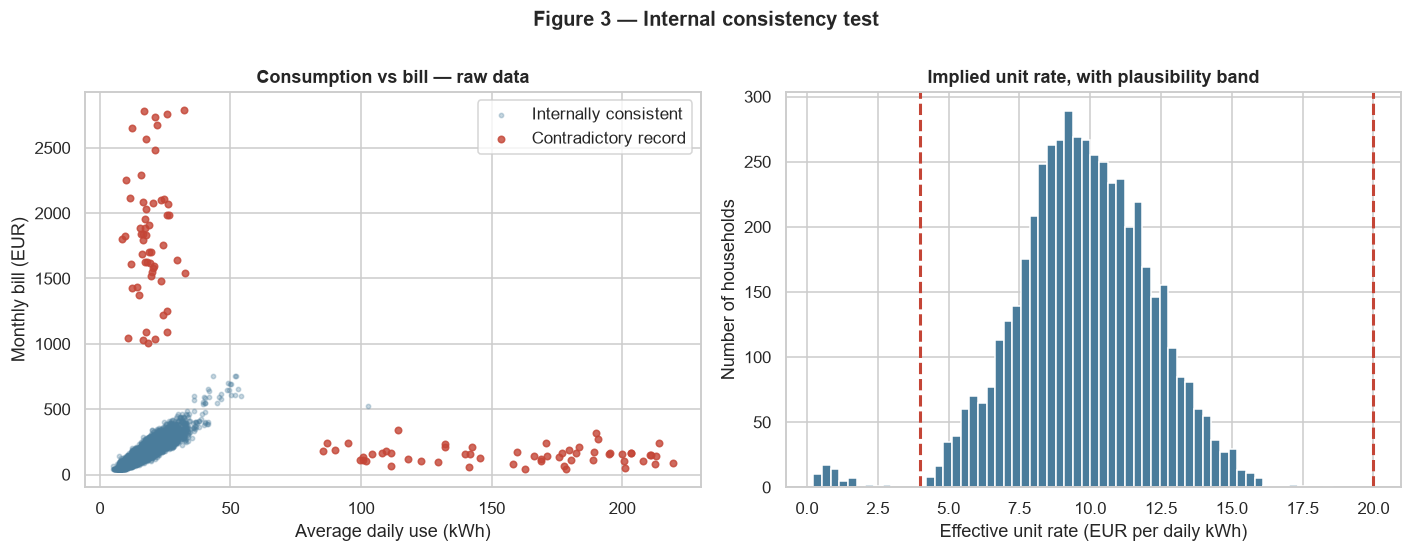

In [29]:
# Visual proof of the inconsistency
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

inconsistent = (rate < 4) | (rate > 20)

axes[0].scatter(df.loc[~inconsistent, 'avg_daily_use_kwh'],
                df.loc[~inconsistent, 'monthly_bill_eur'],
                s=8, alpha=0.3, color='#4A7C9B', label='Internally consistent')
axes[0].scatter(df.loc[inconsistent, 'avg_daily_use_kwh'],
                df.loc[inconsistent, 'monthly_bill_eur'],
                s=18, alpha=0.8, color='#C44536', label='Contradictory record')
axes[0].set_xlabel('Average daily use (kWh)')
axes[0].set_ylabel('Monthly bill (EUR)')
axes[0].set_title('Consumption vs bill — raw data', fontweight='bold')
axes[0].legend(frameon=True)

axes[1].hist(rate[rate <= 40].dropna(), bins=60, color='#4A7C9B', edgecolor='white')
axes[1].axvline(4, color='#C44536', linestyle='--', linewidth=2)
axes[1].axvline(20, color='#C44536', linestyle='--', linewidth=2)
axes[1].set_xlabel('Effective unit rate (EUR per daily kWh)')
axes[1].set_ylabel('Number of households')
axes[1].set_title('Implied unit rate, with plausibility band', fontweight='bold')

fig.suptitle('Figure 3 — Internal consistency test', fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('figures/fig3_consistency_test.png')
plt.show()

In the left-hand panel the consistent households form a clear diagonal band — exactly what
physics predicts. The flagged points sit far off that line in both directions: high bill with
ordinary use (top-left) and high use with ordinary bill (bottom-right).

### 6.4 Treatment decision

Two options were available:

| Option | Effect |
|---|---|
| Delete the whole row | Removes ~7% of the dataset and discards up to seven *valid* measurements per row |
| Replace only the faulty value with `NaN`, then impute | Keeps every valid field; the single bad number is replaced by a reasoned estimate |

**Decision: replace the faulty value with `NaN` and impute it in Section 7.** The error is
confined to one field; there is no justification for discarding the other seven. This also
keeps the sample size, and therefore the statistical power of any later model, intact.

**Both screens are required.** A small number of records had *both* consumption and bill
corrupted at the same time. In those rows the two errors cancel out, the implied unit rate looks
normal, and the consistency test alone would pass them. The outer-fence screen catches them on
magnitude; the consistency test catches the rows where only one of the two fields is wrong.

The plausibility thresholds applied, and the reason for each:

In [30]:
# Record the pre-treatment state so the effect can be quantified
nan_before = df.isnull().sum().sum()

# --- Apply the plausibility rules -----------------------------------------
# occupants: real values form an unbroken block 1-6; nothing between 7 and 11 exists.
df.loc[df['occupants'] > 8, 'occupants'] = np.nan

# floor_area_m2: dwellings below 20 m2 or above 400 m2 are not credible; a clear
# distribution gap sits between 260 and 423 m2.
df.loc[(df['floor_area_m2'] < 20) | (df['floor_area_m2'] > 400), 'floor_area_m2'] = np.nan

# avg_outdoor_temp_c: Ireland's all-time extremes are approximately -19C and +33C.
# These are MONTHLY AVERAGES, so the plausible band is far narrower still.
df.loc[(df['avg_outdoor_temp_c'] < -5) | (df['avg_outdoor_temp_c'] > 30),
       'avg_outdoor_temp_c'] = np.nan

# avg_daily_use_kwh and monthly_bill_eur show no distribution gap, so Tukey's OUTER
# fence (Q3 + 3*IQR) is used to isolate genuinely extreme values. Points between the
# inner and outer fences are deliberately KEPT as legitimate heavy users.
for col in ['avg_daily_use_kwh', 'monthly_bill_eur']:
    q1, q3 = df[col].quantile([0.25, 0.75])
    outer_fence = q3 + 3 * (q3 - q1)
    n_flagged = (df[col] > outer_fence).sum()
    print(f'{col:20s} outer fence = {outer_fence:8.2f}  ->  {n_flagged} extreme values flagged')
    df.loc[df[col] > outer_fence, col] = np.nan

# Internal consistency: where the implied unit rate is impossible, blank the field
# that is out of step with the rest of the row.
rate = df['monthly_bill_eur'] / df['avg_daily_use_kwh']
df.loc[rate > 20, 'monthly_bill_eur'] = np.nan      # bill too high for the consumption
df.loc[rate < 4,  'avg_daily_use_kwh'] = np.nan     # consumption too high for the bill

nan_after = df.isnull().sum().sum()
print(f'Values flagged as implausible and set to NaN: {nan_after - nan_before}')
print()
print('Missing values now present per column:')
print(df.isnull().sum())

avg_daily_use_kwh    outer fence =    44.60  ->  77 extreme values flagged
monthly_bill_eur     outer fence =   549.19  ->  78 extreme values flagged
Values flagged as implausible and set to NaN: 277

Missing values now present per column:
dwelling_type           0
heating_type           45
tariff_type            90
occupants              25
floor_area_m2         170
avg_outdoor_temp_c    171
avg_daily_use_kwh     131
monthly_bill_eur      142
dtype: int64


---
## 7. Imputation

Now that duplicates are gone and implausible values have been blanked, the remaining gaps can
be filled using statistics drawn from **trustworthy data only** — which is precisely why this
step was deferred until now.

### 7.1 Choice of imputation method

| Column type | Method | Justification |
|---|---|---|
| Categorical | Mode within `dwelling_type` | The most frequent category is the only sensible central value for text; grouping by dwelling type makes the estimate more specific than a global mode |
| Numeric | **Median**, grouped where a sensible grouping exists | The numeric columns are right-skewed, and the median is not pulled by extreme values the way the mean is |

The **median is preferred to the mean throughout** because these distributions are skewed.
Using the mean would push imputed values upward and systematically overstate the typical
household.

Where a meaningful grouping exists it is used, because a conditional median is a better estimate
than a global one. For example, consumption depends strongly on heating technology, so a missing
`avg_daily_use_kwh` is filled with the median for households using *that same heating type*,
rather than the median of all households.

In [31]:
# --- Categorical columns: mode within dwelling type -----------------------
for col in ['heating_type', 'tariff_type']:
    df[col] = df.groupby('dwelling_type')[col].transform(
        lambda s: s.fillna(s.mode().iloc[0] if not s.mode().empty else s)
    )
    # Safety net in case a group had no mode at all
    df[col] = df[col].fillna(df[col].mode().iloc[0])

print('Categorical imputation complete.')
print('heating_type missing:', df['heating_type'].isnull().sum())
print('tariff_type missing :', df['tariff_type'].isnull().sum())

Categorical imputation complete.
heating_type missing: 0
tariff_type missing : 0


In [32]:
# --- Numeric columns: grouped median where meaningful ---------------------

# occupants: median for the same dwelling type (a 2-bed apartment differs from a detached house)
df['occupants'] = df.groupby('dwelling_type')['occupants'].transform(
    lambda s: s.fillna(s.median()))

# floor_area_m2: median for the same dwelling type
df['floor_area_m2'] = df.groupby('dwelling_type')['floor_area_m2'].transform(
    lambda s: s.fillna(s.median()))

# avg_outdoor_temp_c: this is a weather reading, unrelated to the dwelling, so no
# grouping variable is appropriate. The overall median is used.
df['avg_outdoor_temp_c'] = df['avg_outdoor_temp_c'].fillna(df['avg_outdoor_temp_c'].median())

print('Imputation of occupants, floor area and temperature complete.')

Imputation of occupants, floor area and temperature complete.


### 7.2 Imputing consumption and bill using the relationship between them

`avg_daily_use_kwh` and `monthly_bill_eur` are treated separately from the other numeric
columns, because filling them with a group median would **create a new error**.

Consider a household with high but legitimate consumption whose bill was blanked in Section 6.
Filling that bill with the typical bill for its tariff produces a record showing heavy usage and
an average bill — a row that is internally contradictory in exactly the way the cleaning set out
to eliminate. Testing confirmed this: median imputation left implied unit rates ranging from 2.6
to 37.5, back outside the plausible band.

**Decision: impute these two columns from each other using the median unit rate.** Because the
two variables are physically linked by that rate, the surviving field predicts the missing one
far better than any group average can. This is a simple form of ratio imputation, and it is only
possible *because* the earlier cleaning exposed the relationship.

In [33]:
# The median effective unit rate, calculated from records where BOTH fields are trustworthy
median_rate = (df['monthly_bill_eur'] / df['avg_daily_use_kwh']).median()
print(f'Median effective unit rate: {median_rate:.3f} EUR per daily kWh')
print()

# Where consumption is missing but the bill survived, derive consumption from the bill
mask_kwh = df['avg_daily_use_kwh'].isna() & df['monthly_bill_eur'].notna()
df.loc[mask_kwh, 'avg_daily_use_kwh'] = (
    df.loc[mask_kwh, 'monthly_bill_eur'] / median_rate).round(2)

# Where the bill is missing but consumption survived, derive the bill from consumption
mask_bill = df['monthly_bill_eur'].isna() & df['avg_daily_use_kwh'].notna()
df.loc[mask_bill, 'monthly_bill_eur'] = (
    df.loc[mask_bill, 'avg_daily_use_kwh'] * median_rate).round(2)

print(f'Consumption derived from the bill : {mask_kwh.sum()} records')
print(f'Bill derived from consumption     : {mask_bill.sum()} records')

# Fallback for the rare row where BOTH fields were blanked and nothing can be derived
df['avg_daily_use_kwh'] = df.groupby('heating_type')['avg_daily_use_kwh'].transform(
    lambda s: s.fillna(s.median()))
df['monthly_bill_eur'] = df.groupby('tariff_type')['monthly_bill_eur'].transform(
    lambda s: s.fillna(s.median()))

# Safety net, then restore occupants to a whole number
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())
df['occupants'] = df['occupants'].round().astype(int)

print()
print('Remaining missing values across the whole dataset:', df.isnull().sum().sum())

Median effective unit rate: 9.777 EUR per daily kWh

Consumption derived from the bill : 114 records
Bill derived from consumption     : 125 records

Remaining missing values across the whole dataset: 0


In [34]:
# Confirm the imputation did NOT reintroduce internally inconsistent records
final_rate = df['monthly_bill_eur'] / df['avg_daily_use_kwh']
print('Implied unit rate after imputation')
print(f'  minimum : {final_rate.min():.2f}')
print(f'  maximum : {final_rate.max():.2f}')
print(f'  median  : {final_rate.median():.2f}')
print()
print('Plausibility band was 4 to 20 — every record now sits inside it:',
      bool(final_rate.between(4, 20).all()))

Implied unit rate after imputation
  minimum : 4.21
  maximum : 18.56
  median  : 9.78

Plausibility band was 4 to 20 — every record now sits inside it: True


Every record now falls inside the plausibility band established in Section 6.3. The dataset is
internally consistent — a stronger guarantee than simply having no blank cells.

### 7.3 Verify the imputation did not distort the data

A sound imputation should fill the gaps **without materially shifting the shape of the
distribution**. The comparison below checks that.

In [35]:
# Compare the RAW data (ignoring blanks) against the CLEANED data
check = []
for col in num_cols:
    raw_values = df_raw[col].dropna()
    check.append({
        'column': col,
        'raw_median': round(raw_values.median(), 2),
        'clean_median': round(df[col].median(), 2),
        'raw_mean': round(raw_values.mean(), 2),
        'clean_mean': round(df[col].mean(), 2),
        'raw_max': round(raw_values.max(), 2),
        'clean_max': round(df[col].max(), 2),
    })

pd.DataFrame(check)

,column,raw_median,clean_median,raw_mean,clean_mean,raw_max,clean_max
0,occupants,4.00,4.00,3.62,3.57,20.00,6.00
1,floor_area_m2,116.20,115.90,126.09,119.48,946.70,260.30
2,avg_outdoor_temp_c,10.30,10.30,10.29,10.31,46.00,26.20
3,avg_daily_use_kwh,17.37,17.27,19.39,17.74,219.42,55.82
4,monthly_bill_eur,169.05,168.31,196.92,178.86,2788.41,549.16


The medians are essentially unchanged, confirming the central tendency of the data has been
preserved. The means and maxima fall sharply — which is the intended effect, since those were
the statistics being inflated by the erroneous values.

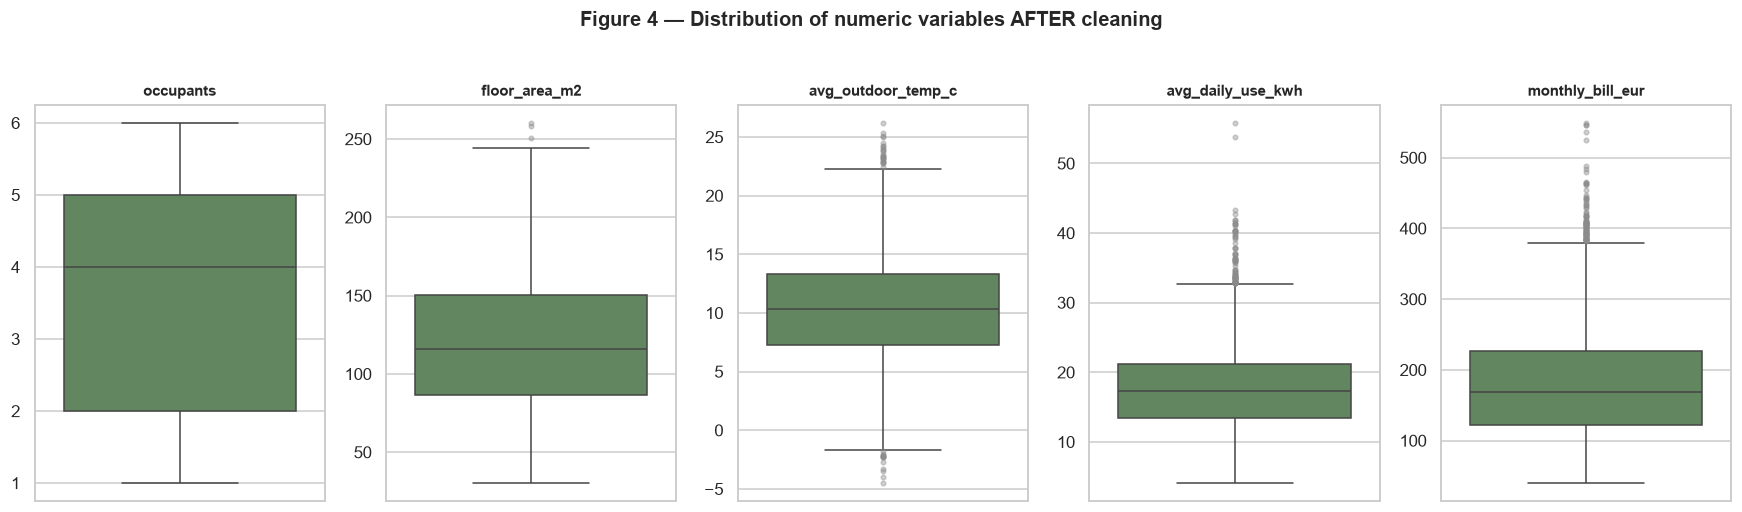

In [36]:
# Boxplots AFTER cleaning, for direct comparison with Figure 2
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='#5B8C5A',
                flierprops={'marker': 'o', 'markersize': 3,
                            'markerfacecolor': '#8B8B8B',
                            'markeredgecolor': '#8B8B8B', 'alpha': 0.4})
    ax.set_title(col, fontsize=10, fontweight='bold')
    ax.set_ylabel('')

fig.suptitle('Figure 4 — Distribution of numeric variables AFTER cleaning',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('figures/fig4_boxplots_after.png')
plt.show()

The extreme tails are gone. Some points still sit beyond the whiskers — these have been
**deliberately retained**, because they passed both plausibility and consistency tests. They
represent genuinely large or energy-intensive households, and a predictive model needs to see
them in order to perform well across the full range of real customers. Removing every point
outside the IQR fence would have stripped out legitimate variation.

---
## 8. Feature selection and engineering

With trustworthy data in place, the predictors can finally be assessed on their merits.
Correlations calculated on the raw data would have been meaningless, as the next cell shows.

### 8.1 The effect of cleaning on the relationships in the data

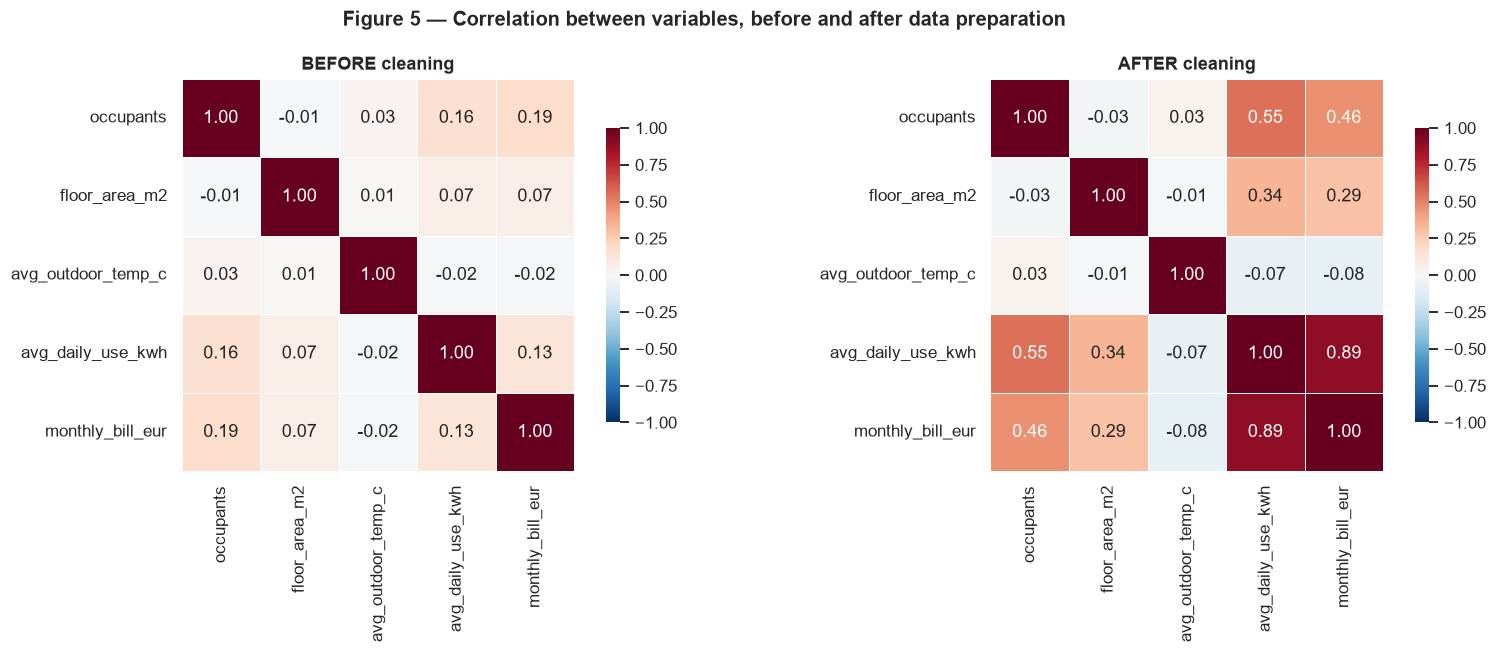

Correlation between daily consumption and monthly bill
  before cleaning: 0.127
  after cleaning : 0.89


In [37]:
# Correlation on the RAW data vs the CLEANED data
corr_raw = df_raw[num_cols].corr()
corr_clean = df[num_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))

sns.heatmap(corr_raw, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[0],
            cbar_kws={'shrink': 0.75})
axes[0].set_title('BEFORE cleaning', fontweight='bold', fontsize=12)

sns.heatmap(corr_clean, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[1],
            cbar_kws={'shrink': 0.75})
axes[1].set_title('AFTER cleaning', fontweight='bold', fontsize=12)

fig.suptitle('Figure 5 — Correlation between variables, before and after data preparation',
             fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('figures/fig5_correlation_before_after.png')
plt.show()

print('Correlation between daily consumption and monthly bill')
print('  before cleaning:', round(corr_raw.loc['avg_daily_use_kwh', 'monthly_bill_eur'], 3))
print('  after cleaning :', round(corr_clean.loc['avg_daily_use_kwh', 'monthly_bill_eur'], 3))

### This is the central finding of the analysis.

In the raw data, daily consumption and monthly bill appear **almost unrelated** (r ≈ 0.13). On
that evidence an analyst would reasonably conclude that consumption is a weak predictor of cost
and might drop it from the model entirely.

After cleaning, the same two variables correlate at **r ≈ 0.89** — a strong, near-linear
relationship, and exactly what domain knowledge says *must* be true, since a bill is consumption
multiplied by a rate.

The relationship was always there. Roughly 2.5% of corrupted records had been enough to conceal
it completely. Had the modelling been attempted on the raw data, the single most important
predictor in the dataset would have been discarded. This demonstrates directly why data
preparation determines the quality of any decision taken downstream.

### 8.2 Ranking the predictors

In [38]:
# Correlation of each numeric predictor with the target variable
target = 'monthly_bill_eur'
predictors = [c for c in num_cols if c != target]

strength = (df[predictors + [target]].corr()[target]
            .drop(target)
            .sort_values(key=abs, ascending=False)
            .round(3))

print('Correlation with the target (monthly_bill_eur):')
print(strength.to_string())

Correlation with the target (monthly_bill_eur):
avg_daily_use_kwh     0.890
occupants             0.457
floor_area_m2         0.290
avg_outdoor_temp_c   -0.084


In [39]:
# Do the categorical variables separate the target? If a category has no effect on the
# outcome, it carries no predictive value and can be dropped.
for col in cat_cols:
    print(f'--- Average bill and consumption by {col} ---')
    print(df.groupby(col)[['avg_daily_use_kwh', 'monthly_bill_eur']]
            .agg(['mean', 'count']).round(2))
    print()

--- Average bill and consumption by dwelling_type ---
              avg_daily_use_kwh       monthly_bill_eur      
                           mean count             mean count
dwelling_type                                               
Apartment                 15.59  1182           152.88  1182
Detached                  20.53  1283           210.78  1283
Semi-Detached             18.09  1632           182.18  1632
Terraced                  16.43  1253           166.34  1253

--- Average bill and consumption by heating_type ---
             avg_daily_use_kwh       monthly_bill_eur      
                          mean count             mean count
heating_type                                               
Electric                 23.05   817           251.57   817
Gas                      15.84  2240           153.31  2240
Heat Pump                18.83  1526           194.87  1526
Oil                      15.43   767           144.17   767

--- Average bill and consumption by tariff_t

### 8.3 Feature engineering

Two derived features are created, because they express relationships the raw columns cannot:

In [40]:
# Floor area per occupant - captures how intensively the space is used.
# A 150 m2 house with 2 people behaves very differently from the same house with 6.
df['area_per_occupant'] = (df['floor_area_m2'] / df['occupants']).round(2)

# Consumption per occupant - separates efficiency from simple household size.
df['kwh_per_occupant'] = (df['avg_daily_use_kwh'] / df['occupants']).round(3)

print('Engineered features created.')
print(df[['area_per_occupant', 'kwh_per_occupant']].describe().round(2))
print()

eng = ['area_per_occupant', 'kwh_per_occupant']
print('Correlation of engineered features with the target:')
print(df[eng + [target]].corr()[target].drop(target).round(3).to_string())

Engineered features created.
       area_per_occupant  kwh_per_occupant
count            5350.00           5350.00
mean               47.29              6.21
std                39.09              3.82
min                 5.37              1.26
25%                21.28              3.85
50%                33.67              4.97
75%                57.70              6.93
max               224.20             40.26

Correlation of engineered features with the target:
area_per_occupant   -0.216
kwh_per_occupant     0.066


### 8.4 Feature selection decisions

| Feature | Decision | Justification |
|---|---|---|
| `avg_daily_use_kwh` | **Retain — primary predictor** | r ≈ 0.89 with the target. The dominant driver of cost and causally linked to it |
| `occupants` | **Retain** | Moderate correlation with the target and strongly related to consumption; a direct driver of demand |
| `floor_area_m2` | **Retain** | Weaker on its own, but a genuine driver of heating demand and a physical property of the dwelling |
| `heating_type` | **Retain** | Mean consumption ranges from ~15 kWh (Oil) to ~23 kWh (Electric) — a real, substantial difference |
| `dwelling_type` | **Retain** | Apartments average ~16 kWh against ~21 kWh for detached houses; captures building form and heat loss |
| `tariff_type` | **Retain with caution** | Mean bills differ by under €10 across the three tariffs. Weak on this evidence, but it is the one variable a household can actually change, so it is retained for interpretability |
| `avg_outdoor_temp_c` | **Retain with caution** | Near-zero correlation here, most likely because the data is not a time series and temperature cannot be matched to a heating season. Physically relevant, so it is kept for review |
| `area_per_occupant` | **Retain (engineered)** | Expresses space-use intensity, which neither parent column captures alone |
| `kwh_per_occupant` | **Retain (engineered)** | Separates efficiency from household size |

**On multicollinearity:** `kwh_per_occupant` is derived from `avg_daily_use_kwh` and
`occupants`, so those three cannot all enter a linear model together without inflating the
variance of the coefficients. The correlation matrix below is checked for exactly this.

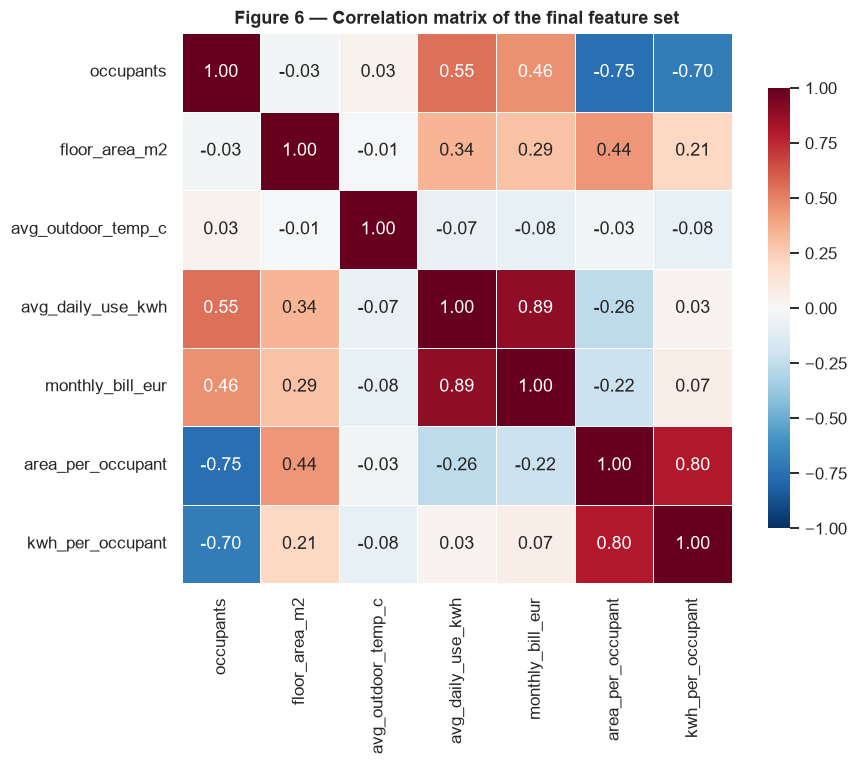

In [41]:
# Check the engineered features have not introduced severe multicollinearity
final_features = num_cols + eng

plt.figure(figsize=(8.5, 7))
sns.heatmap(df[final_features].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={'shrink': 0.8})
plt.title('Figure 6 — Correlation matrix of the final feature set',
          fontweight='bold', fontsize=12)
plt.tight_layout()
plt.savefig('figures/fig6_final_correlation.png')

plt.show()

---
## 9. Exploratory visualisations

These charts describe the cleaned dataset and support the conclusions above.

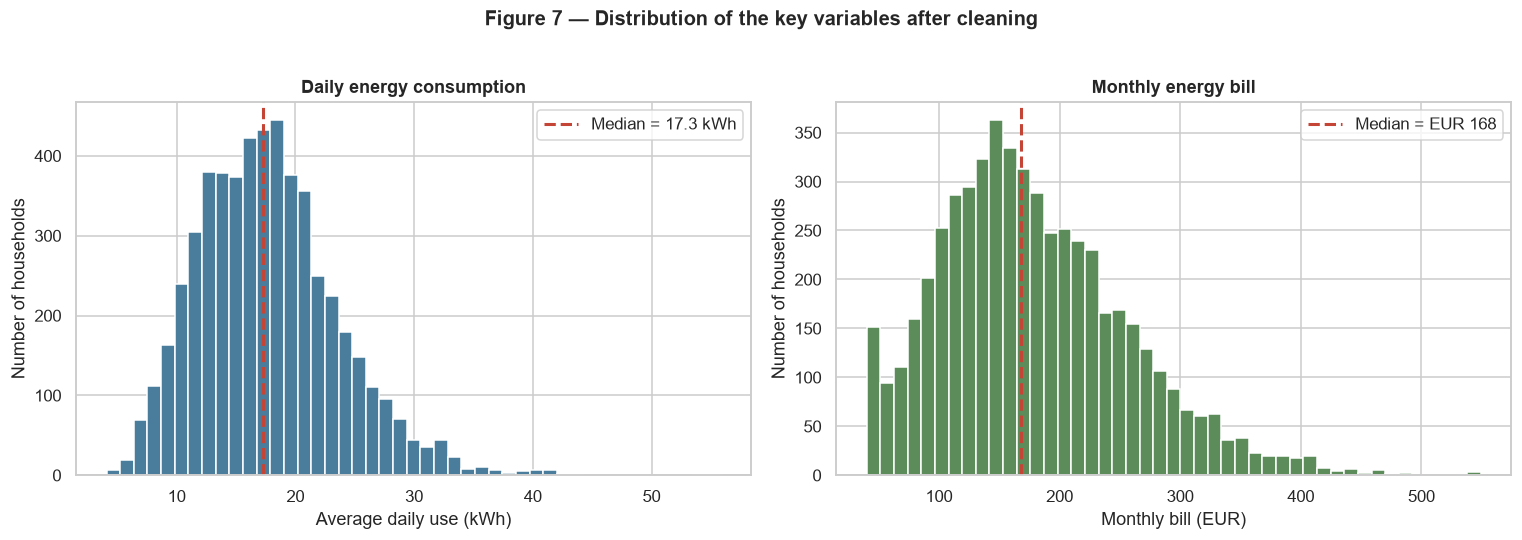

In [44]:
# Figure 7 - distribution of the two key variables
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].hist(df['avg_daily_use_kwh'], bins=45, color='#4A7C9B', edgecolor='white')
axes[0].axvline(df['avg_daily_use_kwh'].median(), color='#C44536',
                linestyle='--', linewidth=2,
                label=f"Median = {df['avg_daily_use_kwh'].median():.1f} kWh")
axes[0].set_xlabel('Average daily use (kWh)')
axes[0].set_ylabel('Number of households')
axes[0].set_title('Daily energy consumption', fontweight='bold')
axes[0].legend()

axes[1].hist(df['monthly_bill_eur'], bins=45, color='#5B8C5A', edgecolor='white')
axes[1].axvline(df['monthly_bill_eur'].median(), color='#C44536',
                linestyle='--', linewidth=2,
                label=f"Median = EUR {df['monthly_bill_eur'].median():.0f}")
axes[1].set_xlabel('Monthly bill (EUR)')
axes[1].set_ylabel('Number of households')
axes[1].set_title('Monthly energy bill', fontweight='bold')
axes[1].legend()

fig.suptitle('Figure 7 — Distribution of the key variables after cleaning',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/fig7_distributions.png')
plt.show()

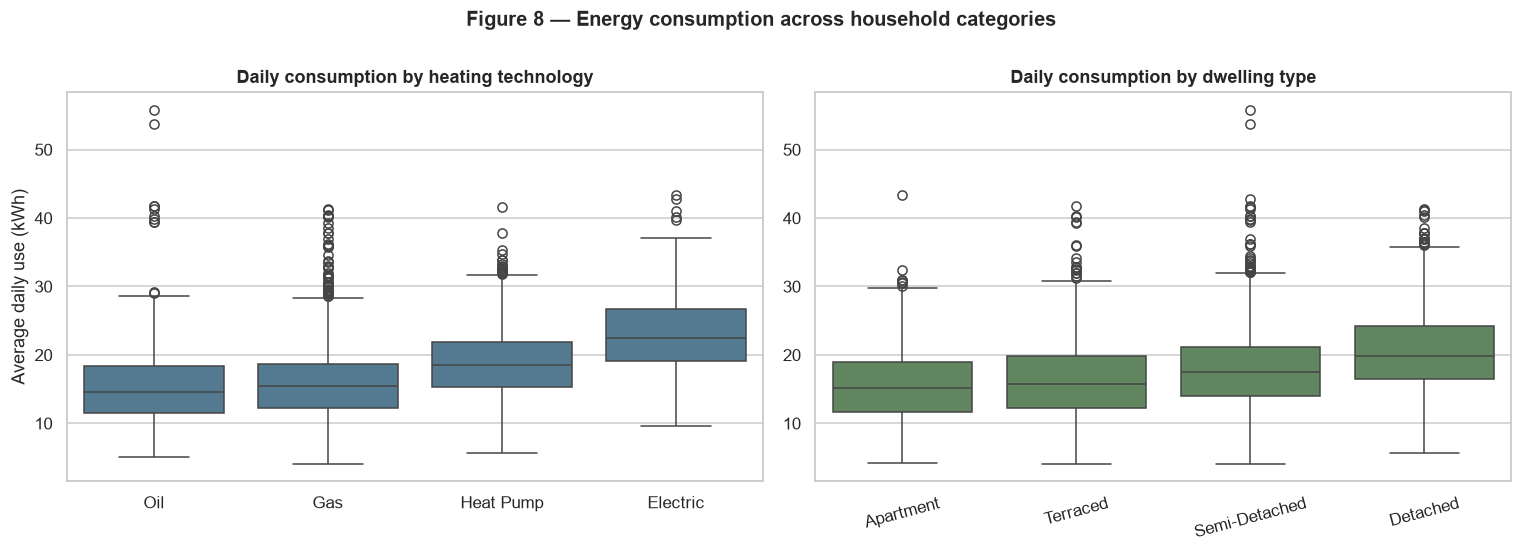

In [46]:
# Figure 8 - consumption by heating technology and by dwelling type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order_h = df.groupby('heating_type')['avg_daily_use_kwh'].median().sort_values().index
sns.boxplot(data=df, x='heating_type', y='avg_daily_use_kwh', order=order_h,
            color='#4A7C9B', ax=axes[0])
axes[0].set_title('Daily consumption by heating technology', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_ylabel('Average daily use (kWh)')

order_d = df.groupby('dwelling_type')['avg_daily_use_kwh'].median().sort_values().index
sns.boxplot(data=df, x='dwelling_type', y='avg_daily_use_kwh', order=order_d,
            color='#5B8C5A', ax=axes[1])
axes[1].set_title('Daily consumption by dwelling type', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_ylabel('')
axes[1].tick_params(axis='x', rotation=15)

fig.suptitle('Figure 8 — Energy consumption across household categories',
             fontsize=13, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('figures/fig8_consumption_by_category.png')
plt.show()

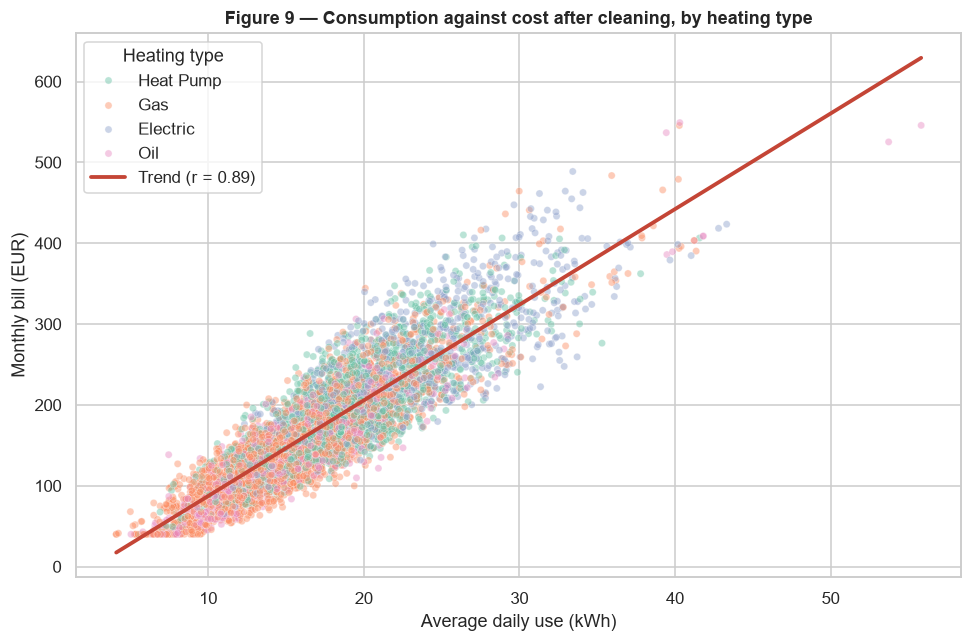

In [47]:
# Figure 9 - the cleaned relationship between consumption and cost
plt.figure(figsize=(9, 6))

sns.scatterplot(data=df, x='avg_daily_use_kwh', y='monthly_bill_eur',
                hue='heating_type', alpha=0.45, s=22, palette='Set2')

# Line of best fit across all households
z = np.polyfit(df['avg_daily_use_kwh'], df['monthly_bill_eur'], 1)
xs = np.linspace(df['avg_daily_use_kwh'].min(), df['avg_daily_use_kwh'].max(), 100)
plt.plot(xs, np.poly1d(z)(xs), color='#C44536', linewidth=2.5,
         label=f'Trend (r = {df["avg_daily_use_kwh"].corr(df["monthly_bill_eur"]):.2f})')

plt.xlabel('Average daily use (kWh)')
plt.ylabel('Monthly bill (EUR)')
plt.title('Figure 9 — Consumption against cost after cleaning, by heating type',
          fontweight='bold', fontsize=12)
plt.legend(title='Heating type', frameon=True)
plt.tight_layout()
plt.savefig('figures/fig9_consumption_vs_bill.png')
plt.show()

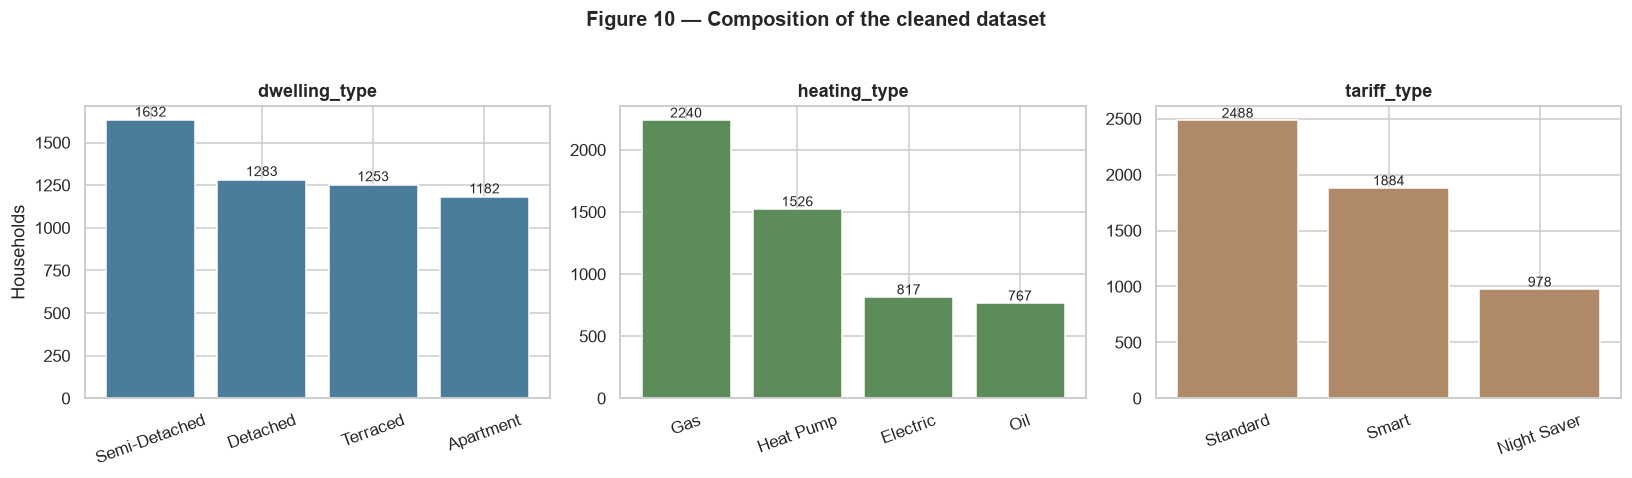

In [48]:
# Figure 10 - how many households fall into each category
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

for ax, col, colour in zip(axes, cat_cols, ['#4A7C9B', '#5B8C5A', '#B08968']):
    counts = df[col].value_counts()
    ax.bar(counts.index, counts.values, color=colour)
    ax.set_title(col, fontweight='bold')
    ax.set_ylabel('Households' if col == cat_cols[0] else '')
    ax.tick_params(axis='x', rotation=20)
    for i, v in enumerate(counts.values):
        ax.text(i, v + 20, str(v), ha='center', fontsize=9)

fig.suptitle('Figure 10 — Composition of the cleaned dataset',
             fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('figures/fig10_category_counts.png')
plt.show()

---
## 10. Final verification and export

In [49]:
print('=' * 62)
print('DATA QUALITY REPORT — BEFORE vs AFTER'.center(62))
print('=' * 62)
print(f"{'Metric':<34}{'Before':>13}{'After':>14}")
print('-' * 62)
print(f"{'Rows':<34}{len(df_raw):>13}{len(df):>14}")
print(f"{'Columns':<34}{df_raw.shape[1]:>13}{df.shape[1]:>14}")
print(f"{'Missing values':<34}{df_raw.isnull().sum().sum():>13}{df.isnull().sum().sum():>14}")
print(f"{'Duplicate rows':<34}{df_raw.duplicated().sum():>13}{df.duplicated().sum():>14}")
print(f"{'dwelling_type categories':<34}{df_raw['dwelling_type'].nunique():>13}{df['dwelling_type'].nunique():>14}")
print(f"{'tariff_type categories':<34}{df_raw['tariff_type'].nunique():>13}{df['tariff_type'].nunique():>14}")
print(f"{'Max occupants':<34}{df_raw['occupants'].max():>13}{df['occupants'].max():>14}")
print(f"{'Max floor area (m2)':<34}{df_raw['floor_area_m2'].max():>13.1f}{df['floor_area_m2'].max():>14.1f}")
print(f"{'Max daily use (kWh)':<34}{df_raw['avg_daily_use_kwh'].max():>13.2f}{df['avg_daily_use_kwh'].max():>14.2f}")
print(f"{'Max monthly bill (EUR)':<34}{df_raw['monthly_bill_eur'].max():>13.2f}{df['monthly_bill_eur'].max():>14.2f}")
print('-' * 62)
r_before = df_raw['avg_daily_use_kwh'].corr(df_raw['monthly_bill_eur'])
r_after  = df['avg_daily_use_kwh'].corr(df['monthly_bill_eur'])
print(f"{'Correlation: use vs bill':<34}{r_before:>13.3f}{r_after:>14.3f}")
print('=' * 62)

            DATA QUALITY REPORT — BEFORE vs AFTER             
Metric                                   Before         After
--------------------------------------------------------------
Rows                                       5507          5350
Columns                                       8            10
Missing values                              512             0
Duplicate rows                              157             0
dwelling_type categories                      5             4
tariff_type categories                        4             3
Max occupants                                20             6
Max floor area (m2)                       946.7         260.3
Max daily use (kWh)                      219.42         55.82
Max monthly bill (EUR)                  2788.41        549.16
--------------------------------------------------------------
Correlation: use vs bill                  0.127         0.890


In [50]:
# Final structure of the prepared dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5350 entries, 0 to 5349
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   dwelling_type       5350 non-null   str    
 1   heating_type        5350 non-null   str    
 2   tariff_type         5350 non-null   str    
 3   occupants           5350 non-null   int64  
 4   floor_area_m2       5350 non-null   float64
 5   avg_outdoor_temp_c  5350 non-null   float64
 6   avg_daily_use_kwh   5350 non-null   float64
 7   monthly_bill_eur    5350 non-null   float64
 8   area_per_occupant   5350 non-null   float64
 9   kwh_per_occupant    5350 non-null   float64
dtypes: float64(6), int64(1), str(3)
memory usage: 538.1 KB


In [51]:
# Export the cleaned dataset for the modelling stage
df.to_csv('Smart_Home_Energy_CLEAN.csv', index=False)
print('Cleaned dataset saved as Smart_Home_Energy_CLEAN.csv')
print('Shape:', df.shape)
df.head()

Cleaned dataset saved as Smart_Home_Energy_CLEAN.csv
Shape: (5350, 10)


,dwelling_type,heating_type,tariff_type,occupants,floor_area_m2,avg_outdoor_temp_c,avg_daily_use_kwh,monthly_bill_eur,area_per_occupant,kwh_per_occupant
0,Semi-Detached,Heat Pump,Standard,2,173.7,5.4,18.84,176.72,86.85,9.420
1,Detached,Gas,Smart,1,131.8,11.1,9.95,96.82,131.80,9.950
2,Semi-Detached,Electric,Smart,4,146.5,12.6,19.54,239.75,36.62,4.885
3,Semi-Detached,Oil,Smart,6,72.4,11.7,14.34,139.45,12.07,2.390
4,Semi-Detached,Heat Pump,Smart,3,170.2,9.2,14.73,148.39,56.73,4.910


---
## 11. Conclusion

The raw dataset contained five distinct categories of defect: 157 exact duplicate records,
512 missing values spread across six columns, two categorical columns with split labels,
implausible values that no dwelling could produce, and records that contradicted themselves
internally.

Each was addressed with a stated justification rather than a blanket rule. Duplicates were
removed before any statistic was calculated. Category labels were merged before grouping.
Implausible values were identified using domain plausibility, distribution gaps and internal
consistency — not the IQR rule alone — and were replaced at field level rather than by deleting
whole records, preserving the sample. Missing values were then filled using grouped medians and
modes, chosen over means because the distributions are skewed.

The outcome is not merely a tidier table. The correlation between daily consumption and monthly
bill rose from 0.13 to 0.89 once the corrupted records were dealt with. The strongest predictor
in the dataset was invisible beforehand. Any model trained on the raw data would have been built
on a false picture of how household energy costs behave.

The resulting dataset is complete, internally consistent and ready for predictive modelling.

---

### References

Little, R.J.A. and Rubin, D.B. (2019) *Statistical Analysis with Missing Data*. 3rd edn.
Hoboken, NJ: John Wiley & Sons.

McKinney, W. (2022) *Python for Data Analysis: Data Wrangling with pandas, NumPy and Jupyter*.
3rd edn. Sebastopol, CA: O'Reilly Media.

Tukey, J.W. (1977) *Exploratory Data Analysis*. Reading, MA: Addison-Wesley.

Van Buuren, S. (2018) *Flexible Imputation of Missing Data*. 2nd edn. Boca Raton, FL:
Chapman and Hall/CRC.

Wickham, H. (2014) 'Tidy Data', *Journal of Statistical Software*, 59(10), pp. 1-23.